# ДЗ 11: Процесс проведения эксперимента: дизайн, подведение результатов. Разбор кейса

## Делаем импорты и читаем данные

In [3]:
from typing import Iterable, Optional
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, ttest_ind, chisquare

In [4]:
user_week_metrics = pd.read_csv("user_week_metrics.csv")
users = pd.read_csv("users.csv")

In [5]:
display(user_week_metrics)
display(users)

,week_start,user_id,user_type,vacancy_views_app,responses_app,relevant_responses_app,invitations_app,responses_emp,relevant_responses_emp,invitations_emp
0,2026-03-09,10000146,APPLICANT,16.0,1.0,1.0,0.0,NaN,NaN,NaN
1,2026-03-09,10000500,APPLICANT,16.0,2.0,1.0,0.0,NaN,NaN,NaN
2,2026-03-09,10001679,APPLICANT,60.0,14.0,9.0,0.0,NaN,NaN,NaN
3,2026-03-09,10002834,APPLICANT,23.0,8.0,4.0,0.0,NaN,NaN,NaN
4,2026-03-09,10003079,APPLICANT,46.0,3.0,2.0,1.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
870680,2026-05-04,98990498,APPLICANT,30.0,6.0,3.0,3.0,NaN,NaN,NaN
870681,2026-05-04,98990683,APPLICANT,15.0,1.0,0.0,0.0,NaN,NaN,NaN
870682,2026-05-04,98990842,APPLICANT,12.0,1.0,1.0,0.0,NaN,NaN,NaN
870683,2026-05-04,98990950,APPLICANT,5.0,0.0,0.0,0.0,NaN,NaN,NaN


,user_id,user_type,reg_date,region_group,platform,company_size
0,57423229,APPLICANT,2020-08-19,Города-миллионники,mobile_web,NaN
1,93238947,APPLICANT,2024-04-09,Москва и СПб,desktop,NaN
2,82066772,APPLICANT,2026-02-08,Города-миллионники,app,NaN
3,31583398,APPLICANT,2025-08-15,Москва и СПб,desktop,NaN
4,46764711,APPLICANT,2024-08-21,Остальные,desktop,NaN
...,...,...,...,...,...,...
387995,35022596,APPLICANT,2020-07-14,Москва и СПб,app,NaN
387996,93581057,APPLICANT,2024-10-09,Города-миллионники,mobile_web,NaN
387997,37175024,APPLICANT,2019-05-24,Города-миллионники,mobile_web,NaN
387998,11416478,APPLICANT,2026-03-01,Москва и СПб,mobile_web,NaN


## Гипотеза

Если после отклика на вакансию показать блок "Похожие вакансии", на которые можно откликнуться в один клик (изменение), то соискатель откликнется на большее количество подходящих ему вакансий, потому что ему не придется возвращаться в поиск, релевантные варианты уже будут перед глазами в момент высокой мотивации (механизм), за счет чего среднее число релевантных откликов на соискателя вырастет минимум на 1.7% (целевая метрика).

| Корзина | Метрика | Тип теста | $\alpha$ | Участие в дизайне (MDE) |
| :--- | :--- | :--- | :--- | :--- |
| Целевая | `relevant_responses_app` на соискателя | двусторонний | 0.05 | да |
| Guardrail | `invitations_app` на соискателя | односторонний | 0.05 | да |
| Информац. | `responses_app`, `vacancy_views_app`, доля релевантных | двусторонний | 0.001 | нет |

- Единица рандомизации: соискатель

- Популяция: соискатели, совершившие хотя бы один отклик за период эксперимента

- Trigger event: отклик пользователя

## MDE по данным

### Проверка качества данных

In [6]:
# функция из лекции Кирилла Гулиева
def summarize_dq(df: pd.DataFrame, key_cols: Optional[Iterable[str]] = None) -> pd.DataFrame:
    # Быстрая сводка по качеству данных: размер, дубли, пропуски по колонкам,
    # при указании ключа считаем также дубли по ключу.
    rows = []
    rows.append({"проверка": "строк всего", "значение": len(df)})
    rows.append({"проверка": "полных дублей строк", "значение": int(df.duplicated().sum())})
    for c in df.columns:
        rows.append({"проверка": f"пропуски: {c}", "значение": int(df[c].isna().sum())})
    if key_cols:
        key_cols = list(key_cols)
        rows.append({
            "проверка": f"дубли по ключу: {'+'.join(key_cols)}",
            "значение": int(df.duplicated(key_cols).sum()),
        })
    return pd.DataFrame(rows)

display(summarize_dq(users, key_cols=["user_id"]))
display(summarize_dq(user_week_metrics, key_cols=["week_start", "user_id"]))

,проверка,значение
0,строк всего,388000
1,полных дублей строк,0
2,пропуски: user_id,0
3,пропуски: user_type,0
4,пропуски: reg_date,0
5,пропуски: region_group,8000
6,пропуски: platform,8000
7,пропуски: company_size,380000
8,дубли по ключу: user_id,0


,проверка,значение
0,строк всего,870685
1,полных дублей строк,0
2,пропуски: week_start,0
3,пропуски: user_id,0
4,пропуски: user_type,0
5,пропуски: vacancy_views_app,47147
6,пропуски: responses_app,47147
7,пропуски: relevant_responses_app,47147
8,пропуски: invitations_app,47147
9,пропуски: responses_emp,823538


In [7]:
applicants_with_company_size_cnt = (
    (users["user_type"] == "APPLICANT")
    & users["company_size"].notna()
).sum()

print(f"Количество соискателей с указанным размером компании: {applicants_with_company_size_cnt}")

Количество соискателей с указанным размером компании: 0


In [8]:
employers_with_applicant_stats_cnt = (
    (user_week_metrics["user_type"] == "EMPLOYER")
    & (
        user_week_metrics["vacancy_views_app"].notna()
        | user_week_metrics["responses_app"].notna()
        | user_week_metrics["relevant_responses_app"].notna()
        | user_week_metrics["invitations_app"].notna()
    )
).sum()

print(f"Количество работодателей с записями, принадлежащими соискателям: {employers_with_applicant_stats_cnt}")

Количество работодателей с записями, принадлежащими соискателям: 0


In [9]:
employers_with_applicant_fields_cnt = (
    (users["user_type"] == "EMPLOYER")
    & (users["region_group"].notna() | users["platform"].notna())
).sum()

print(f"Количество работодателей с заполненными полями соискателей: {employers_with_applicant_fields_cnt}")

Количество работодателей с заполненными полями соискателей: 0


In [10]:
applicants_with_employer_stats_cnt = (
    (user_week_metrics["user_type"] == "APPLICANT")
    & (
        user_week_metrics["responses_emp"].notna()
        | user_week_metrics["relevant_responses_emp"].notna()
        | user_week_metrics["invitations_emp"].notna()
    )
).sum()

print(f"Количество соискателей с записями, принадлежащими работодателям: {applicants_with_employer_stats_cnt}")

Количество соискателей с записями, принадлежащими работодателям: 0


In [11]:
invalid_hierarchy_cnt = (
    (user_week_metrics["user_type"] == "APPLICANT")
    & (
        (user_week_metrics["invitations_app"] < 0)
        | (user_week_metrics["invitations_app"] > user_week_metrics["relevant_responses_app"])
        | (user_week_metrics["relevant_responses_app"] > user_week_metrics["responses_app"])
    )
).sum()

print(f"Нарушений иерархии метрик у соискателей: {invalid_hierarchy_cnt}")

Нарушений иерархии метрик у соискателей: 0


In [12]:
display(user_week_metrics.describe(percentiles=[0.95, 0.99, 0.999]))

,user_id,vacancy_views_app,responses_app,relevant_responses_app,invitations_app,responses_emp,relevant_responses_emp,invitations_emp
count,8.706850e+05,823538.000000,823538.000000,823538.000000,823538.000000,47147.000000,47147.000000,47147.000000
mean,5.449465e+07,29.063800,5.376111,2.684591,0.330681,17.856237,8.953147,2.350796
std,2.569065e+07,48.209464,11.505925,3.614972,0.875104,52.938546,25.653696,7.628092
min,1.000015e+07,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
95%,9.449894e+07,74.000000,14.000000,8.000000,2.000000,71.000000,36.000000,10.000000
99%,9.807960e+07,157.000000,35.000000,15.000000,4.000000,195.000000,100.000000,27.000000
99.9%,9.889941e+07,629.463000,156.000000,35.000000,8.000000,549.708000,296.708000,83.708000
max,9.899981e+07,7388.000000,1680.000000,244.000000,60.000000,4724.000000,1486.000000,499.000000


- Технических аномалий (отрицательных значений, нарушений иерархии) нет, а длинный правый хвост — это суперактивные пользователи / автоотклики, которых не удаляем, чтобы не занизить СКО и MDE.

In [13]:
applicants = user_week_metrics[user_week_metrics["user_type"] == "APPLICANT"]

weekly = (
    applicants.groupby("week_start", as_index=False)
    .agg(
        users=("user_id", "nunique"),
        views=("vacancy_views_app", "mean"),
        responses=("responses_app", "mean"),
        relevant=("relevant_responses_app", "mean"),
        invitations=("invitations_app", "mean"),
        rel_sum=("relevant_responses_app", "sum"),
        resp_sum=("responses_app", "sum"),
    )
    .assign(relevant_share=lambda d: d["rel_sum"] / d["resp_sum"])
)

display(weekly)

,week_start,users,views,responses,relevant,invitations,rel_sum,resp_sum,relevant_share
0,2026-03-09,102701,28.928063,5.342392,2.690568,0.330435,276324.0,548669.0,0.503626
1,2026-03-16,103872,28.718750,5.289192,2.669950,0.328828,277333.0,549399.0,0.504793
2,2026-03-23,103090,28.747764,5.326103,2.701717,0.332030,278520.0,549068.0,0.507260
3,2026-03-30,101859,28.980885,5.329249,2.695128,0.330977,274523.0,542832.0,0.505724
4,2026-04-06,102791,29.019515,5.342131,2.691559,0.331478,276668.0,549123.0,0.503836
5,2026-04-13,103926,29.107509,5.374324,2.723255,0.332641,283017.0,558532.0,0.506716
6,2026-04-20,102599,28.832523,5.316904,2.681030,0.328736,275071.0,545509.0,0.504246
7,2026-04-27,53178,30.247414,5.708808,2.667250,0.337640,141839.0,303583.0,0.467217
8,2026-05-04,49522,30.105832,5.668531,2.575986,0.322443,127568.0,280717.0,0.454436


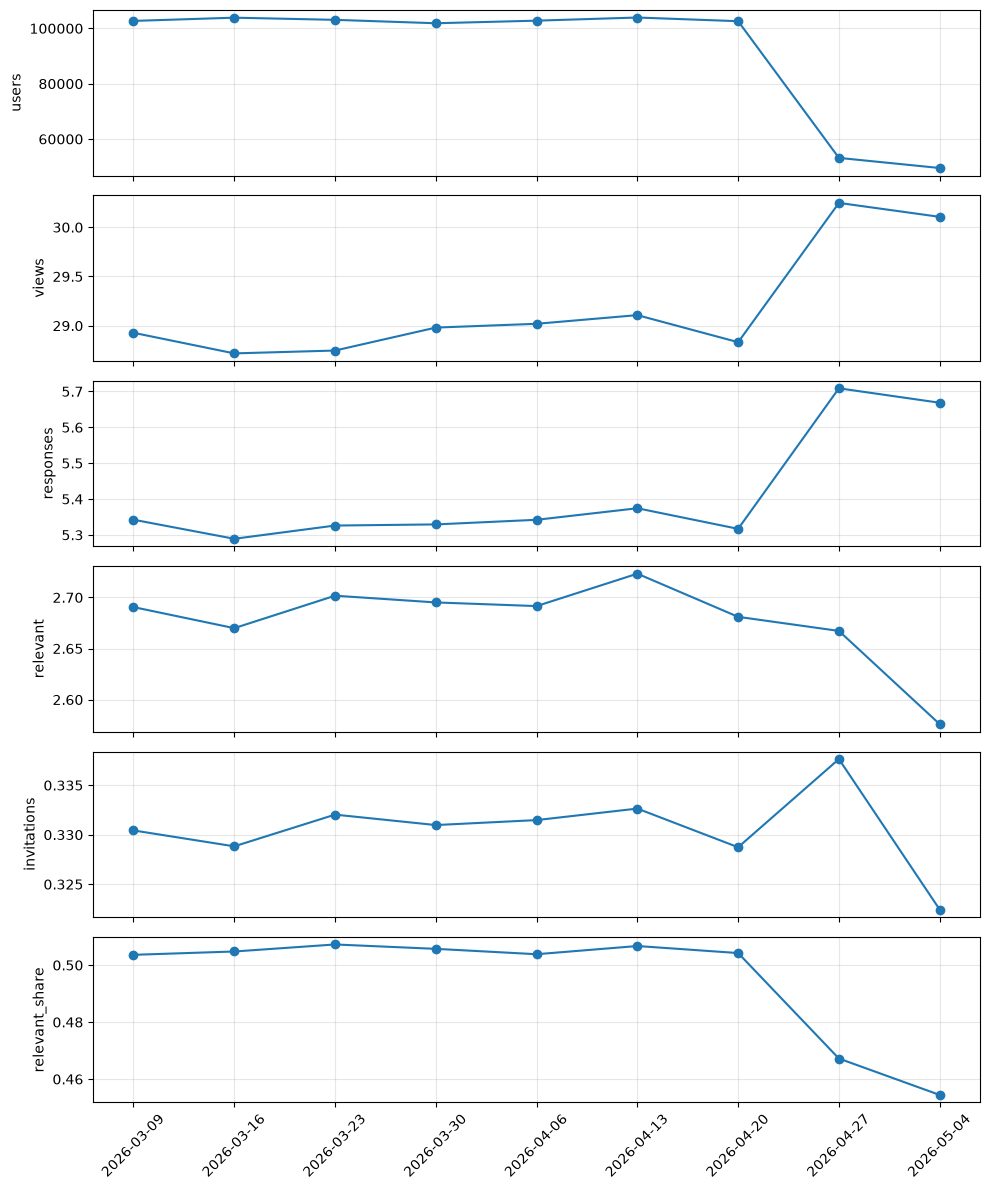

In [14]:
metrics = ["users", "views", "responses", "relevant", "invitations", "relevant_share"]
fig, axes = plt.subplots(len(metrics), 1, figsize=(10, 12), sharex=True)

for ax, col in zip(axes, metrics):
    ax.plot(weekly["week_start"], weekly[col], marker="o")
    ax.set_ylabel(col)
    ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

По динамике изменения метрик можно заметить, что начиная с 2026-04-27 происходит обвал количества пользователей, рост количества просмотров и откликов, а количество и доля релевантных откликов падает. Это можно связать с сезонностью "майских праздников": соискателей становится меньше, а те, что остаются - наиболее замотивированы и начинают откликаться чаще. Рекомендуется не проводить эксперимент в этот период, чтобы не делать поправку на сезонность.

> Для прогноза MDE берем стабильные 7 недель 2026-03-09 по 2026-04-20, а праздничные 2026-04-27 и 2026-05-04 исключаем.

### Расчёт MDE

In [15]:
applicants_clean = applicants[(applicants["week_start"] != "2026-04-27") & (applicants["week_start"] != "2026-05-04")]

clean_weeks = sorted(applicants_clean["week_start"].unique())

def calc_mde_pct(series, alpha=0.05, power=0.80, two_sided=True):
    n = len(series) / 2
    mean = series.mean()
    std = series.std(ddof=1)
    z_alpha = norm.ppf(1 - alpha / 2) if two_sided else norm.ppf(1 - alpha)
    z_beta = norm.ppf(power)
    mde_abs = (z_alpha + z_beta) * std * np.sqrt(2 / n)
    return mde_abs / mean * 100

rows = []
for k in range(1, 6):
    window_weeks = clean_weeks[:k]
    window_df = applicants_clean[applicants_clean["week_start"].isin(window_weeks)]

    user_metrics = (
        window_df.groupby("user_id", as_index=False)
        .agg(
            responses=("responses_app", "sum"),
            relevant=("relevant_responses_app", "sum"),
            invitations=("invitations_app", "sum"),
        )
    )
    population = user_metrics[user_metrics["responses"] > 0]

    rows.append({
        "weeks": k,
        "n_per_group": len(population) / 2,
        "mde_relevant_pct": calc_mde_pct(population["relevant"], two_sided=True),
        "mde_invitations_pct": calc_mde_pct(population["invitations"], two_sided=False),
    })

mde_table = pd.DataFrame(rows)
display(mde_table)

,weeks,n_per_group,mde_relevant_pct,mde_invitations_pct
0,1,47337.5,1.972366,3.895197
1,2,78191.5,1.694218,3.096424
2,3,99173.5,1.584928,2.758656
3,4,114300.5,1.555415,2.616386
4,5,125810.5,1.539175,2.532222


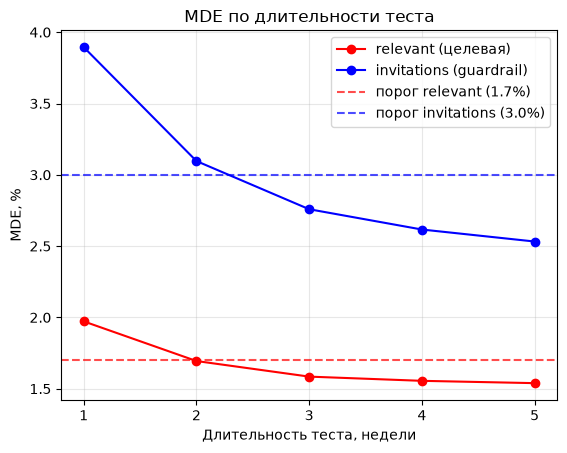

In [16]:
plt.plot(mde_table["weeks"], mde_table["mde_relevant_pct"], color="red", marker="o", label="relevant (целевая)")
plt.plot(mde_table["weeks"], mde_table["mde_invitations_pct"], color="blue", marker="o", label="invitations (guardrail)")

plt.axhline(1.7, color="red", linestyle="--", alpha=0.7, label="порог relevant (1.7%)")
plt.axhline(3.0, color="blue", linestyle="--", alpha=0.7, label="порог invitations (3.0%)")

plt.xticks(mde_table["weeks"])
plt.xlabel("Длительность теста, недели")
plt.ylabel("MDE, %")
plt.title("MDE по длительности теста")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

- Популяция: соискатели, совершившие хотя бы один отклик за период окна
- Метрика на пользователя: сумма релевантных откликов и сумма приглашений на одного соискателя за все окно длительностью k недель
- По графику видим, что MDE сначала быстро снижается, а затем замедляется и выходит на плато. Происходит это по трем причинам:
    - MDE обратно пропорционален квадратному корню из числа пользователей
    - некоторые пользователи из прошлых недель возвращаются в новые
    - при расширении окна начинает меняться сама метрика (другая дисперсия и более тяжелые хвосты у возвращающихся пользователей)

## Длительность

- MDE: Можно было бы взять две недели для запуска теста, но порог по guardrail метрике не достигается за 2 недели
- Календарь: тест проводим с 5 апреля по 25 апреля 2027 года. Эти даты не попадают на какие-либо праздники, которые могут повлиять на тест. Держать тест дольше - не стоит, так как за 3 недели мы уже достигаем необходимого MDE, а дальше недели начинают попадать на майские праздники, на которых по истории 2026 года трафик и релевантность обваливаются
- Недельные циклы: выбор связан с разным поведением пользователей в будни и выходные:
    - в будни высокий трафик, работают работодатели и рекрутеры
    - в выходные аудитория менее активна, чаще заходит с телефона, работодатели и рекрутеры отдыхают
    - поэтому берём целое число недель (21 день), чтобы будни и выходные попали в равной пропорции и оценка не перекосилась


> Для продакта: за 3 недели теста мы заметим просадку приглашений от 2.76% и изменение релевантных откликов от 1.58% с вероятностью 80% (мощность теста) 

## Риски

- Пересечения с другими экспериментами: нельзя запускать другие эксперименты, которые триггерятся после отклика соискателя или меняют путь соискателя до отклика. Если пользователь попадет в два теста на одном экране, фичи начнут влиять друг на друга, и величина эффекта сместится. В идеале не пересекаться нигде, но на практике запрещаем параллельные тесты на экране теста
- Праздники:
    -  если эксперимент попадет на майские праздники, то изменится состав аудитории и ее поведение (остаются самые мотивированные соискатели, работодатели отдыхают), а значит, что придется делать поправки на обвал трафика и релевантности, что значительно усложняет оценку
    - если разработка задержится и тест будет попадать на майские праздники, то переносим старт на период после праздников, а не пытаемся досчитать с поправкой

- Мониторинг во время теста и условия остановки:
    - Смотрим на размеры тестовой и контрольной групп (SRM) используя хи квадрат тест с порогом p < 0.001
    - Следим за полнотой данных: нужно чтобы все события и дни сохранились без пропусков
    - Аномалии: метрики резко упали или выросли в разы (возможен баг)
    - Останавливаем: при триггере SRM или явном баге/обвале метрик
    - Не останавливаем и не продлеваем по промежуточному p-value - это проблема peeking: пока тест идет, p-value случайно гуляет вверх-вниз; если остановимся при первом p < 0.05, то реальная доля ложных прокрасов взлетает с 5% в несколько раз, то же происходит и с продлением. Длительность теста фиксируется заранее
- Срезы: 
    - Когорты: users.region_group, users.reg_date
    - Срезы: users.platform
- Множественные сравнения:
    - Если проверять множество сегментов на обычном alpha = 0.05, то быстро растёт FWER (вероятность хотя бы одной ложной находки)
    - Заранее фиксируем список сегментов, которые смотрим
    - Применяем поправку Холма
    - Эффект, найденный в отдельном срезе - гипотеза для следующего эксперимента, а не повод принимать решение по основному тесту

## A/A на истории

In [17]:
aa_user_metrics = (
    applicants_clean[applicants_clean["week_start"].isin(clean_weeks[:3])]
    .groupby("user_id", as_index=False)
    .agg(
        responses=("responses_app", "sum"),
        relevant=("relevant_responses_app", "sum")
    )
)

aa_population = aa_user_metrics[aa_user_metrics["responses"] > 0]

rng = np.random.default_rng(42)
values = aa_population["relevant"].to_numpy()

n_total = len(values)
n_test, n_control = 0, 0

pvalues = []
for i in range(1000):
    mask = rng.random(len(aa_population)) < 0.5

    if i == 0:
        n_test = mask.sum()
        n_control = (~mask).sum()

    ttest = ttest_ind(values[mask], values[~mask], equal_var=False)
    pvalues.append(ttest.pvalue)

pvalues = np.array(pvalues)

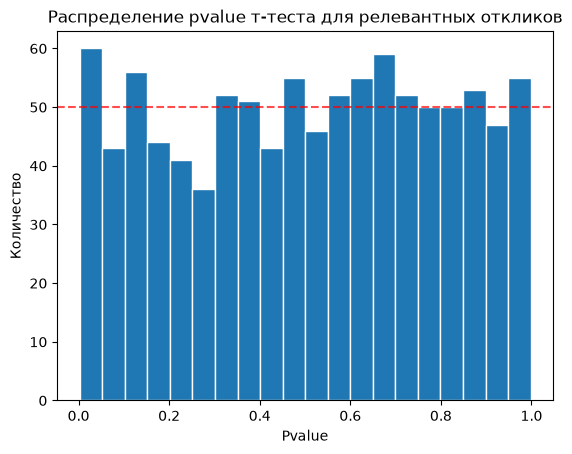

Количество прокрасов: 56
Доля прокрасов: 0.056


In [18]:
plt.hist(pvalues, bins=20, edgecolor="white")
plt.title("Распределение pvalue т-теста для релевантных откликов")
plt.xlabel("Pvalue")
plt.ylabel("Количество")
plt.axhline(50, color="red", linestyle="--", alpha=0.7)
plt.show()
print(f"Количество прокрасов: {(pvalues < 0.05).sum()}")
print(f"Доля прокрасов: {(pvalues < 0.05).mean()}")

- При 1000 запусках и alpha=0.05 ожидаемый разброс около 50 +- 2 * sqrt(1000 * 0.05 * 0.95) ~ (3.6%–6.4%), распределение p-value равномерное — значит, t-тест Уэлча корректно держит уровень ошибки I рода даже несмотря на длинный правый хвост нашей метрики

In [19]:
p_srm = chisquare([n_control, n_test], f_exp=[n_total / 2, n_total / 2]).pvalue
print(f"Размер контрольной группы: {n_control}")
print(f"Размер тестовой группы: {n_test}")
print(f"P-value хи квадрат теста для разбиений: {p_srm}")

Размер контрольной группы: 99220
Размер тестовой группы: 99127
P-value хи квадрат теста для разбиений: 0.8345894938487843


- P-value для хи квадрат теста явно больше порога в 0.001
- SRM не обнаружен, рандомизация работает корректно